# Consumer Complaint Trends and Company Response Analysis
### Bank of America complaint records | CFPB data | May 2017 – August 2023

**Programme:** Programme Experience Lab Internship Programme  
**Project:** Week 4 – Consumer Complaint Trends and Response  
**Analytical focus:** Exploratory data analysis, statistical testing, complaint-forwarding intervals and recorded company responses.

---

## 1. Executive overview

This notebook analyses the supplied consumer complaint records to identify patterns in complaint volumes, financial products, reported issues, company response classifications and the time taken by the Consumer Financial Protection Bureau (CFPB) to forward complaints to the company.

The analysis follows a reproducible workflow: inspect the raw data, validate and prepare fields, conduct exploratory analysis, test selected hypotheses, interpret results in a financial-services context, and document limitations.

> **Interpretation principle:** A consumer complaint is a report of an issue. It does not, by itself, establish misconduct, prove a regulatory violation or establish that the reported issue is factually correct.

### Scope and data note

The project brief describes 62,516 complaint records relating to Bank of America, covering 1 May 2017 to 28 August 2023. The supplied flat file contains 12 fields and does not include a company-name column. Therefore, this notebook analyses the supplied records as the project-provided Bank of America extract; the institution label cannot be independently verified from a company field in this file.

### Key definitions

- **Date submitted:** Date the CFPB received the complaint.
- **Date received:** Date the CFPB sent the complaint to the company.
- **Forwarding interval:** Calendar days between the two dates. This is **not** the company's response or resolution time.
- **Timely response?:** Recorded indicator of whether the company provided a timely response. Blank values are retained as missing and are not recoded to “No”.

## 2. Research questions and hypotheses

The following questions are testable using the supplied fields. Hypotheses are stated before examining inferential results to reduce the risk of selecting tests solely to support observed patterns.

| ID | Research question | Null hypothesis (H₀) | Alternative hypothesis (H₁) | Planned method |
|---|---|---|---|---|
| RQ1 | Are complaint-forwarding intervals similar across financial product categories? | Forwarding-interval distributions are the same across products. | At least one product has a different forwarding-interval distribution. | Kruskal–Wallis test |
| RQ2 | Is the recorded company response category associated with product category? | Product and response category are independent. | Product and response category are associated. | Chi-square test of independence |
| RQ3 | Is the proportion of complaints marked as receiving a timely response different across reporting years? | Timely-response status is independent of reporting year. | Timely-response status is associated with reporting year. | Chi-square test of independence |
| RQ4 | Is there a monotonic trend in monthly complaint volume over the observation period? | There is no monotonic association between time and monthly complaint volume. | Monthly complaint volume has a monotonic association with time. | Spearman rank correlation |

**Significance level:** α = 0.05. P-values are interpreted alongside effect sizes, sample sizes and practical significance. Statistical association is not interpreted as causation.

## 3. Import libraries and configure file paths

The notebook uses pandas and NumPy for data handling, Matplotlib and Seaborn for visualisation, and SciPy for statistical testing. The source files should be kept in the same folder as this notebook, or the paths below should be updated.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
sns.set_palette("deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

def format_p(p_value):
    """Format very small p-values without displaying numerical underflow as zero."""
    return "< 0.001" if p_value < 0.001 else f"= {p_value:.4f}"

DATA_PATH = Path("Consumer_Complaints.xlsx - Data.csv")
DICTIONARY_PATH = Path("ConsumerComplaints_DataDictionary.csv")

# Also support the uploaded execution environment where files are stored in /mnt/data.
if not DATA_PATH.exists() and Path("/mnt/data/Consumer_Complaints.xlsx - Data.csv").exists():
    DATA_PATH = Path("/mnt/data/Consumer_Complaints.xlsx - Data.csv")
if not DICTIONARY_PATH.exists() and Path("/mnt/data/ConsumerComplaints_DataDictionary.csv").exists():
    DICTIONARY_PATH = Path("/mnt/data/ConsumerComplaints_DataDictionary.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError("Complaint data file not found. Place it beside this notebook or update DATA_PATH.")
if not DICTIONARY_PATH.exists():
    raise FileNotFoundError("Data dictionary not found. Place it beside this notebook or update DICTIONARY_PATH.")

print("Complaint data:", DATA_PATH.resolve())
print("Data dictionary:", DICTIONARY_PATH.resolve())

Complaint data: C:\Users\HomePC\Documents\ShopSmart retail analytics data science project\Consumer-Complaint-Trends-and-Company-Response-Analysis\Consumer_Complaints.xlsx - Data.csv
Data dictionary: C:\Users\HomePC\Documents\ShopSmart retail analytics data science project\Consumer-Complaint-Trends-and-Company-Response-Analysis\ConsumerComplaints_DataDictionary.csv


## 4. Load the source files

The complaint extract was supplied as a CSV export of the worksheet named `Data`; it is therefore loaded with `read_csv`. The data dictionary is loaded separately and used to understand the meaning of each field.

In [2]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
data_dictionary = pd.read_csv(DICTIONARY_PATH)

print(f"Raw dataset dimensions: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
print(f"Data dictionary entries: {len(data_dictionary):,}")
display(data_dictionary)
display(raw.head())

Raw dataset dimensions: 62,516 rows × 12 columns
Data dictionary entries: 12


,Field,Description
0,Complaint ID,The unique identification number for a complaint
1,Submitted via,How the complaint was submitted to the CFPB
2,Date submitted,The date the CFPB received the complaint
3,Date received,The date the CFPB sent the complaint to the company
4,State,The state of the mailing address provided by the consumer
5,Product,The type of product the consumer identified in the complaint
6,Sub-product,The type of sub-product the consumer identified in the complaint (not all Products have Sub-products)
7,Issue,The issue the consumer identified in the complaint (possible values are dependent on Product)
8,Sub-issue,"The sub-issue the consumer identified in the complaint (oossible values are dependent on Product and Issue, and not ..."
9,Company public response,"The company's optional, public-facing response to a consumer's complaint. Companies can choose to select a response ..."


,Complaint ID,Submitted via,Date submitted,Date received,State,Product,Sub-product,Issue,Sub-issue,Company public response,Company response to consumer,Timely response?
0,4848023,Referral,2021-10-24,2021-10-27,NY,Mortgage,Conventional home mortgage,Applying for a mortgage or refinancing an existing mortgage,NaN,Company has responded to the consumer and the CFPB and chooses not to provide a public response,Closed with explanation,Yes
1,3621464,Web,2020-04-24,2020-04-24,FL,"Money transfer, virtual currency, or money service",Refund anticipation check,Lost or stolen check,NaN,Company has responded to the consumer and the CFPB and chooses not to provide a public response,Closed with monetary relief,Yes
2,5818349,Web,2022-07-27,2022-07-27,CA,"Credit reporting, credit repair services, or other personal consumer reports",Credit reporting,Incorrect information on your report,Account information incorrect,Company has responded to the consumer and the CFPB and chooses not to provide a public response,Closed with explanation,Yes
3,7233015,Referral,2023-07-10,2023-07-11,CA,Credit card or prepaid card,General-purpose prepaid card,Problem getting a card or closing an account,"Trouble getting, activating, or registering a card",NaN,In progress,NaN
4,5820224,Referral,2022-07-27,2022-07-28,VA,Credit card or prepaid card,General-purpose credit card or charge card,Closing your account,Company closed your account,Company has responded to the consumer and the CFPB and chooses not to provide a public response,Closed with explanation,Yes


## 5. Dataset inspection and initial validation

This section checks the structure, column names, data types, candidate primary key, exact duplicate rows, duplicate complaint identifiers, and the date coverage. These checks are completed before any records are removed or values are changed.

In [3]:
print("Column names:")
print(raw.columns.tolist())

print("\nData types:")
display(raw.dtypes.rename("dtype").to_frame())

print("\nDataset information:")
raw.info()

print("\nDuplicate full rows:", int(raw.duplicated().sum()))
print("Missing Complaint ID values:", int(raw["Complaint ID"].isna().sum()))
print("Duplicate Complaint ID values:", int(raw["Complaint ID"].duplicated().sum()))

date_check = pd.DataFrame()
for col in ["Date submitted", "Date received"]:
    parsed = pd.to_datetime(raw[col], errors="coerce")
    date_check[col] = [
        int(parsed.isna().sum()),
        parsed.min(),
        parsed.max()
    ]
date_check.index = ["Unparseable/missing values", "Earliest date", "Latest date"]
display(date_check)

Column names:
['Complaint ID', 'Submitted via', 'Date submitted', 'Date received', 'State', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Company public response', 'Company response to consumer', 'Timely response?']

Data types:


,dtype
Complaint ID,int64
Submitted via,object
Date submitted,object
Date received,object
State,object
Product,object
Sub-product,object
Issue,object
Sub-issue,object
Company public response,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62516 entries, 0 to 62515
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   Complaint ID                  62516 non-null  int64 
 1   Submitted via                 62516 non-null  object
 2   Date submitted                62516 non-null  object
 3   Date received                 62516 non-null  object
 4   State                         62516 non-null  object
 5   Product                       62516 non-null  object
 6   Sub-product                   62509 non-null  object
 7   Issue                         62516 non-null  object
 8   Sub-issue                     51658 non-null  object
 9   Company public response       60341 non-null  object
 10  Company response to consumer  62516 non-null  object
 11  Timely response?              61022 non-null  object
dtypes: int64(1), object(11)
memory usage: 5.7+ MB

Dupli

,Date submitted,Date received
Unparseable/missing values,0,0
Earliest date,2017-05-01 00:00:00,2017-05-01 00:00:00
Latest date,2023-08-28 00:00:00,2023-08-28 00:00:00


### 5.1 Missing-value assessment

Missingness is examined by column and percentage. Missing `Sub-product`, `Sub-issue` and `Company public response` values are not automatically treated as errors: the data dictionary explains that not all products have sub-products and not all issues have sub-issues; the public response field is optional. Blank timely-response values are kept distinct from “No”.

In [4]:
missing_summary = pd.DataFrame({
    "Missing count": raw.isna().sum(),
    "Missing percentage": (raw.isna().mean() * 100).round(2),
    "Non-missing count": raw.notna().sum()
}).sort_values("Missing percentage", ascending=False)

display(missing_summary)

,Missing count,Missing percentage,Non-missing count
Sub-issue,10858,17.37,51658
Company public response,2175,3.48,60341
Timely response?,1494,2.39,61022
Sub-product,7,0.01,62509
Complaint ID,0,0.00,62516
Submitted via,0,0.00,62516
Date submitted,0,0.00,62516
Date received,0,0.00,62516
State,0,0.00,62516
Product,0,0.00,62516


## 6. Data preparation and cleaning decisions

A separate working copy is created so the original imported dataframe remains unchanged. The cleaning steps are deliberately conservative:

1. Trim leading/trailing whitespace in text fields.
2. Convert date fields to pandas datetime values, with invalid values becoming `NaT`.
3. Convert `Complaint ID` to a string identifier (it is an ID, not a quantity).
4. Preserve missing values rather than replacing them with invented categories.
5. Derive year, month, month-start and forwarding interval fields.
6. Do not delete valid complaints or impute missing response fields.

The supplied data is a flat file. It is not treated as a relational database.

In [5]:
df = raw.copy()

# Preserve an unchanged copy of the original imported data in `raw`.
text_columns = df.select_dtypes(include=["object"]).columns.tolist()
for col in text_columns:
    df[col] = df[col].map(lambda x: x.strip() if isinstance(x, str) else x)

df["Complaint ID"] = df["Complaint ID"].astype("string")
df["Date submitted"] = pd.to_datetime(df["Date submitted"], errors="coerce")
df["Date received"] = pd.to_datetime(df["Date received"], errors="coerce")

# Derived time variables
df["Year"] = df["Date submitted"].dt.year
df["Month"] = df["Date submitted"].dt.month
df["Month name"] = df["Date submitted"].dt.month_name()
df["Month start"] = df["Date submitted"].dt.to_period("M").dt.to_timestamp()
df["Forwarding days"] = (df["Date received"] - df["Date submitted"]).dt.days

# Check derived interval validity
negative_intervals = int((df["Forwarding days"] < 0).sum())
invalid_dates = int(df[["Date submitted", "Date received"]].isna().any(axis=1).sum())

print("Working dataset dimensions:", df.shape)
print("Rows with an unparseable/missing date:", invalid_dates)
print("Negative forwarding intervals:", negative_intervals)
print("Duplicate Complaint IDs after preparation:", int(df["Complaint ID"].duplicated().sum()))

Working dataset dimensions: (62516, 17)
Rows with an unparseable/missing date: 0
Negative forwarding intervals: 0
Duplicate Complaint IDs after preparation: 0


### 6.1 Validation of cleaning decisions

The next checks verify that date ranges are within the project period, forwarding intervals are non-negative, complaint identifiers remain unique, and the expected categories are present. Any unusual value is reported for investigation rather than silently removed.

In [6]:
validation = {
    "Rows": len(df),
    "Columns": df.shape[1],
    "Unique complaint IDs": df["Complaint ID"].nunique(dropna=True),
    "Duplicate complaint IDs": int(df["Complaint ID"].duplicated().sum()),
    "Missing submitted dates": int(df["Date submitted"].isna().sum()),
    "Missing received dates": int(df["Date received"].isna().sum()),
    "Negative forwarding intervals": int((df["Forwarding days"] < 0).sum()),
    "Zero-day forwarding intervals": int((df["Forwarding days"] == 0).sum()),
    "Positive forwarding intervals": int((df["Forwarding days"] > 0).sum()),
}
display(pd.Series(validation, name="Value").to_frame())

print("Submitted date range:", df["Date submitted"].min(), "to", df["Date submitted"].max())
print("Received date range:", df["Date received"].min(), "to", df["Date received"].max())
print("Response categories:", sorted(df["Company response to consumer"].dropna().unique().tolist()))
print("Timely response categories:", sorted(df["Timely response?"].dropna().unique().tolist()))

,Value
Rows,62516
Columns,17
Unique complaint IDs,62516
Duplicate complaint IDs,0
Missing submitted dates,0
Missing received dates,0
Negative forwarding intervals,0
Zero-day forwarding intervals,49634
Positive forwarding intervals,12882


Submitted date range: 2017-05-01 00:00:00 to 2023-08-28 00:00:00
Received date range: 2017-05-01 00:00:00 to 2023-08-28 00:00:00
Response categories: ['Closed', 'Closed with explanation', 'Closed with monetary relief', 'Closed with non-monetary relief', 'In progress']
Timely response categories: ['No', 'Yes']


## 7. Exploratory data analysis (EDA)

### 7.1 Overall complaint profile

The summary below reports the number of complaints, observation period, number of products and issues represented, and the distribution of key categorical fields.

In [7]:
overview = pd.Series({
    "Total complaint records": len(df),
    "Unique complaint IDs": df["Complaint ID"].nunique(),
    "Number of product categories": df["Product"].nunique(),
    "Number of issue categories": df["Issue"].nunique(),
    "Number of states represented": df["State"].nunique(),
    "First submitted date": df["Date submitted"].min().date(),
    "Last submitted date": df["Date submitted"].max().date(),
    "Median forwarding interval (days)": df["Forwarding days"].median(),
    "Mean forwarding interval (days)": round(df["Forwarding days"].mean(), 2)
}, name="Value")
display(overview.to_frame())

,Value
Total complaint records,62516
Unique complaint IDs,62516
Number of product categories,9
Number of issue categories,76
Number of states represented,51
First submitted date,2017-05-01
Last submitted date,2023-08-28
Median forwarding interval (days),0.0
Mean forwarding interval (days),1.22


### 7.2 Annual complaint distribution

Annual totals are useful for describing the broad pattern, but the first and final years are partial observation years (2017 begins in May; 2023 ends in August). Comparisons of raw annual totals must therefore be interpreted with this unequal exposure period in mind.

,Year,Complaints
0,2017,5394
1,2018,7872
2,2019,7075
3,2020,8942
4,2021,11149
5,2022,12953
6,2023,9131


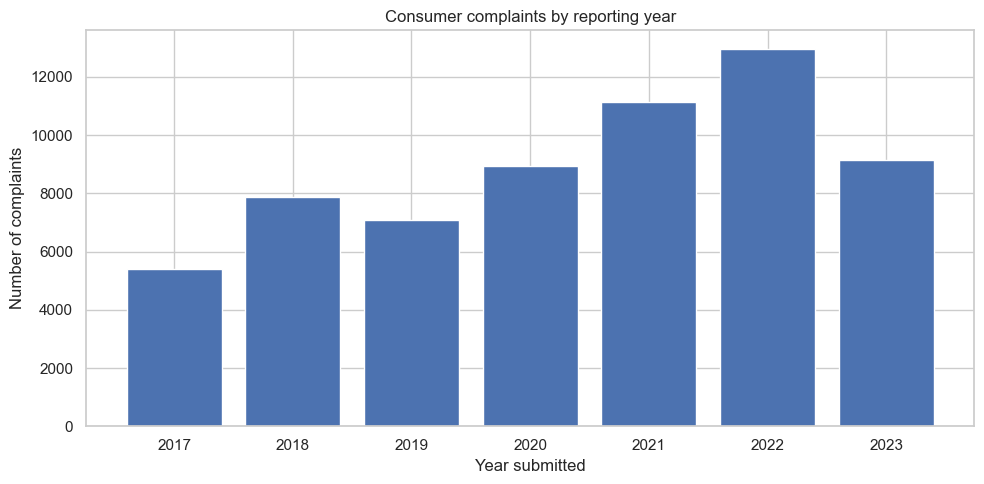

In [8]:
annual_counts = df.groupby("Year").size().rename("Complaints").reset_index()
display(annual_counts)

plt.figure(figsize=(10, 5))
plt.bar(annual_counts["Year"].astype(str), annual_counts["Complaints"])
plt.title("Consumer complaints by reporting year")
plt.xlabel("Year submitted")
plt.ylabel("Number of complaints")
plt.tight_layout()
plt.show()

### 7.3 Monthly complaint distribution and trend

Monthly totals provide a more granular view. Months with zero records, if any, are retained in the complete monthly time series so that missing calendar months are not mistaken for absent observations.

,Month start,Complaints
0,2017-05-01,744
1,2017-06-01,701
2,2017-07-01,701
3,2017-08-01,666
4,2017-09-01,635


,Month start,Complaints
71,2023-04-01,1058
72,2023-05-01,1085
73,2023-06-01,1018
74,2023-07-01,1749
75,2023-08-01,717


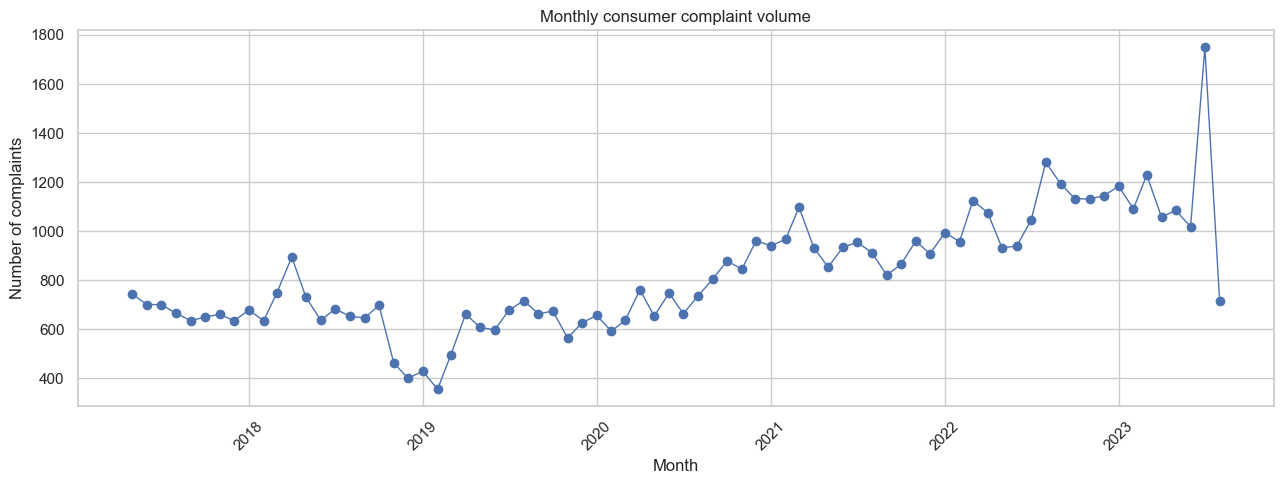

In [9]:
monthly_counts = (
    df.set_index("Date submitted")
      .resample("MS")
      .size()
      .rename("Complaints")
      .reset_index()
      .rename(columns={"Date submitted": "Month start"})
)
display(monthly_counts.head())
display(monthly_counts.tail())

plt.figure(figsize=(13, 5))
plt.plot(monthly_counts["Month start"], monthly_counts["Complaints"], marker="o", linewidth=1)
plt.title("Monthly consumer complaint volume")
plt.xlabel("Month")
plt.ylabel("Number of complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### 7.4 Frequently reported financial products

Complaint counts by product are calculated and visualised. Counts represent the number of records in this extract, not complaint rates per customer or per product account. The dataset does not contain the number of customers or accounts exposed to each product.

,Product,Complaints,Percentage
0,Checking or savings account,24814,39.69
1,Credit card or prepaid card,16197,25.91
2,"Credit reporting, credit repair services, or other personal consumer reports",7710,12.33
3,Mortgage,6601,10.56
4,"Money transfer, virtual currency, or money service",3453,5.52
5,Debt collection,2736,4.38
6,Vehicle loan or lease,633,1.01
7,"Payday loan, title loan, or personal loan",333,0.53
8,Student loan,39,0.06


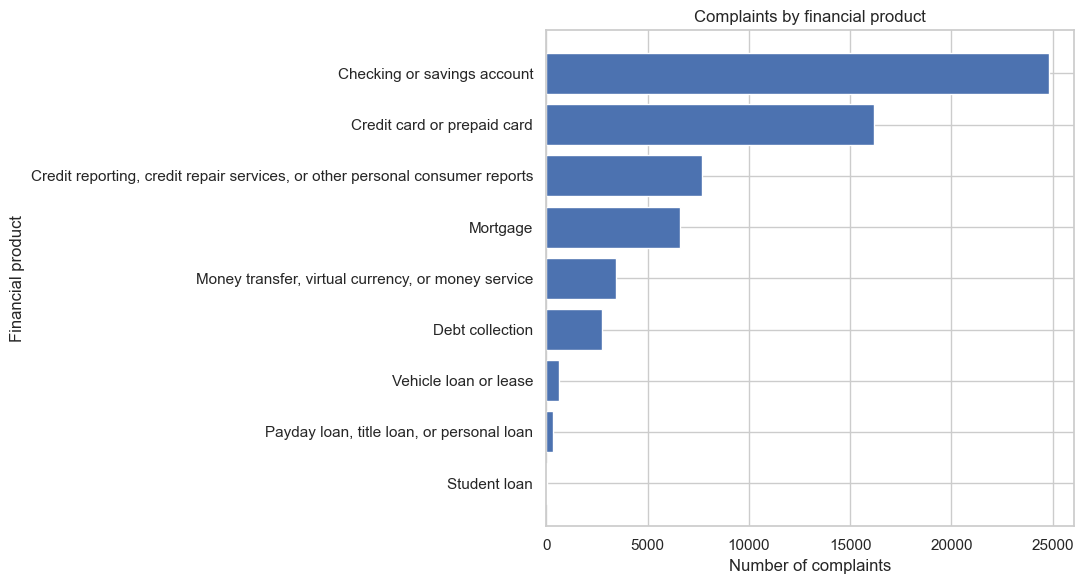

In [10]:
product_counts = df["Product"].value_counts(dropna=False).rename_axis("Product").reset_index(name="Complaints")
product_counts["Percentage"] = (product_counts["Complaints"] / len(df) * 100).round(2)
display(product_counts)

plt.figure(figsize=(11, 6))
plt.barh(product_counts.sort_values("Complaints")["Product"], product_counts.sort_values("Complaints")["Complaints"])
plt.title("Complaints by financial product")
plt.xlabel("Number of complaints")
plt.ylabel("Financial product")
plt.tight_layout()
plt.show()

### 7.5 Frequently reported issues

The most frequently recorded issues are identified overall. The chart displays the ten most common issues to keep labels readable; the full frequency table remains available below.

,Issue,Complaints,Percentage
0,Managing an account,15109,24.17
1,Incorrect information on your report,4931,7.89
2,Problem with a purchase shown on your statement,4415,7.06
3,Closing an account,2953,4.72
4,Trouble during payment process,2827,4.52
5,Opening an account,2725,4.36
6,Problem with a lender or other company charging your account,2493,3.99
7,Fraud or scam,1987,3.18
8,Struggling to pay mortgage,1904,3.05
9,Problem with a credit reporting company's investigation into an existing problem,1876,3.00


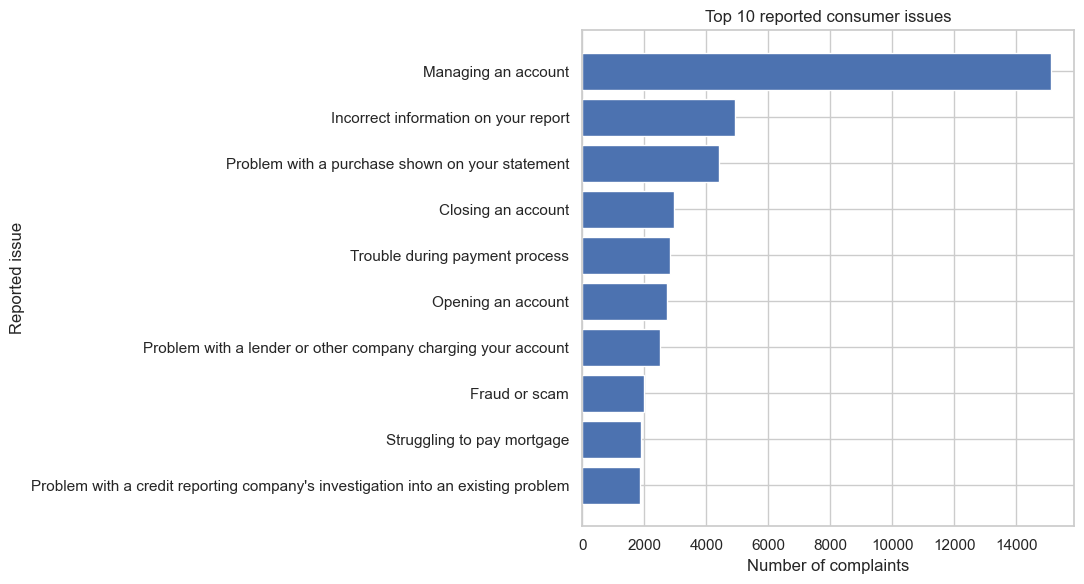

In [11]:
issue_counts = df["Issue"].value_counts().rename_axis("Issue").reset_index(name="Complaints")
issue_counts["Percentage"] = (issue_counts["Complaints"] / len(df) * 100).round(2)
display(issue_counts.head(20))

top_issues = issue_counts.head(10).sort_values("Complaints")
plt.figure(figsize=(11, 6))
plt.barh(top_issues["Issue"], top_issues["Complaints"])
plt.title("Top 10 reported consumer issues")
plt.xlabel("Number of complaints")
plt.ylabel("Reported issue")
plt.tight_layout()
plt.show()

### 7.6 Issues across financial product categories

A cross-tabulation shows how reported issues are distributed across products. For readability, the heatmap focuses on the ten most frequently reported issues. The complete cross-tabulation is retained for further inspection.

Issue,Managing an account,Incorrect information on your report,Problem with a purchase shown on your statement,Closing an account,Trouble during payment process,Opening an account,Problem with a lender or other company charging your account,Fraud or scam,Struggling to pay mortgage,Problem with a credit reporting company's investigation into an existing problem
Product,,,,,,,,,,
Checking or savings account,15109,129,0,2953,0,2725,2493,0,0,20
Credit card or prepaid card,0,411,4415,0,0,0,0,0,0,160
"Credit reporting, credit repair services, or other personal consumer reports",0,4145,0,0,0,0,0,36,0,1641
Debt collection,0,0,0,0,0,0,0,0,0,0
"Money transfer, virtual currency, or money service",0,0,0,0,0,0,0,1951,0,0
Mortgage,0,186,0,0,2827,0,0,0,1904,35
"Payday loan, title loan, or personal loan",0,18,0,0,0,0,0,0,0,1
Student loan,0,5,0,0,0,0,0,0,0,0
Vehicle loan or lease,0,37,0,0,0,0,0,0,0,19


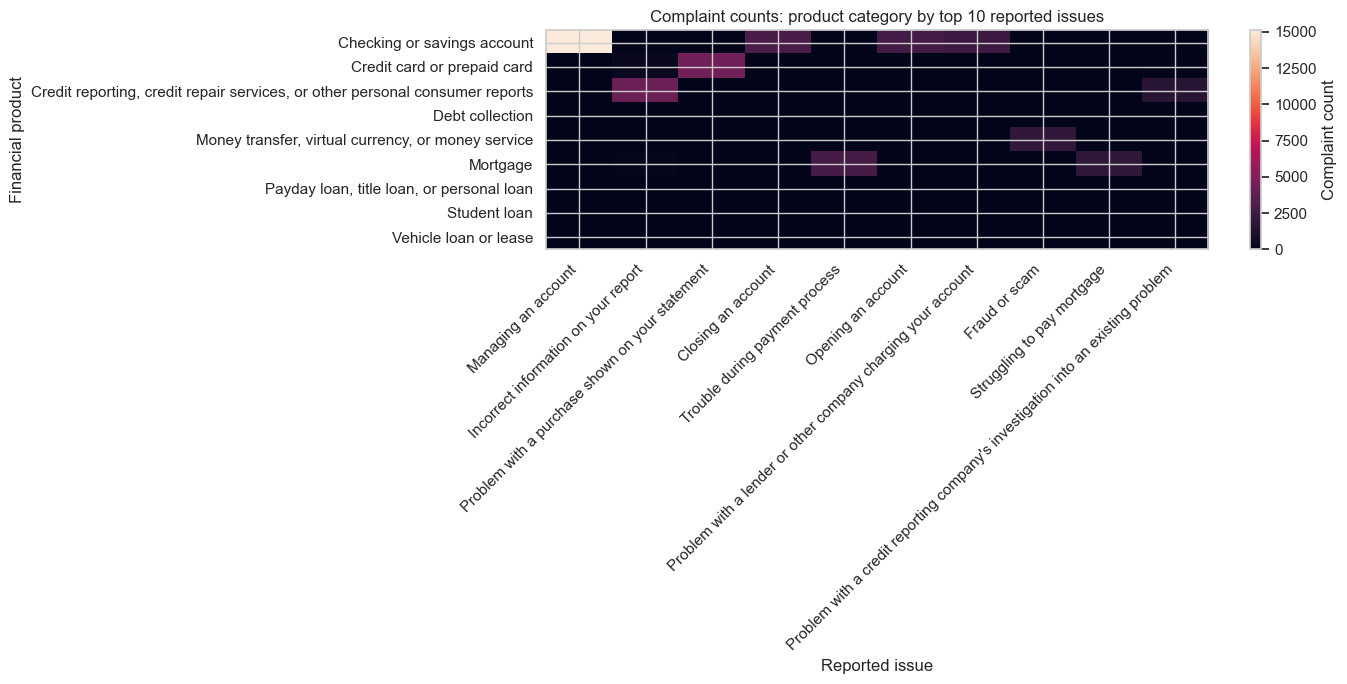

In [12]:
product_issue = pd.crosstab(df["Product"], df["Issue"])
top_issue_names = issue_counts.head(10)["Issue"].tolist()
product_issue_top = product_issue.reindex(columns=top_issue_names, fill_value=0)

display(product_issue_top)

plt.figure(figsize=(14, 7))
plt.imshow(product_issue_top.to_numpy(), aspect="auto", interpolation="nearest")
plt.colorbar(label="Complaint count")
plt.yticks(range(len(product_issue_top.index)), product_issue_top.index)
plt.xticks(range(len(product_issue_top.columns)), product_issue_top.columns, rotation=45, ha="right")
plt.title("Complaint counts: product category by top 10 reported issues")
plt.xlabel("Reported issue")
plt.ylabel("Financial product")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 7.7 Recorded company response categories

The `Company response to consumer` field records how the company responded or the status recorded in the extract. These categories are described as recorded classifications; they should not be interpreted as a complete measure of consumer satisfaction or successful resolution.

,Recorded company response,Complaints,Percentage
0,Closed with explanation,41044,65.65
1,Closed with monetary relief,14697,23.51
2,Closed with non-monetary relief,5273,8.43
3,In progress,1494,2.39
4,Closed,8,0.01


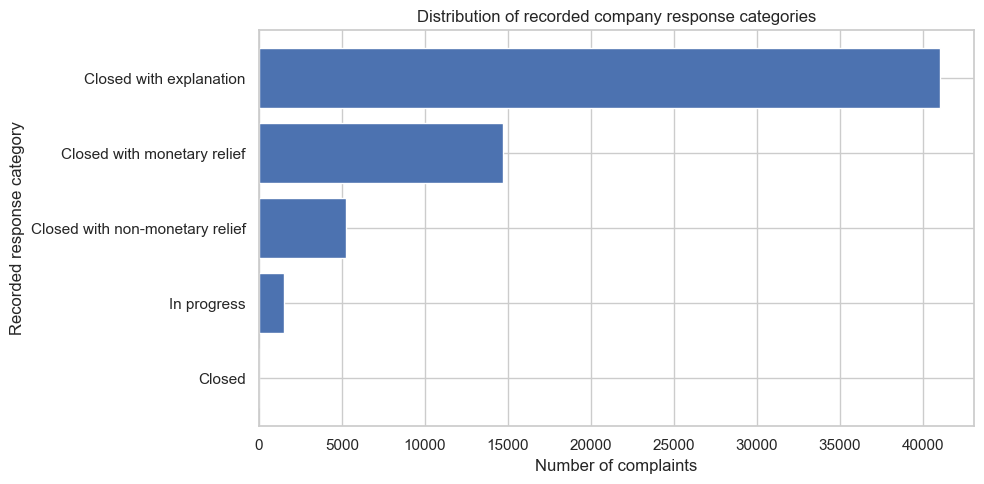

In [13]:
response_counts = df["Company response to consumer"].value_counts(dropna=False).rename_axis(
    "Recorded company response"
).reset_index(name="Complaints")
response_counts["Percentage"] = (response_counts["Complaints"] / len(df) * 100).round(2)
display(response_counts)

plt.figure(figsize=(10, 5))
plt.barh(response_counts.sort_values("Complaints")["Recorded company response"].fillna("Missing"), response_counts.sort_values("Complaints")["Complaints"])
plt.title("Distribution of recorded company response categories")
plt.xlabel("Number of complaints")
plt.ylabel("Recorded response category")
plt.tight_layout()
plt.show()

### 7.8 Timely response indicator

The percentage of complaints marked `Yes` is calculated using records with a non-missing timely-response indicator as the denominator. Blank values remain missing and are reported separately. This avoids treating an in-progress complaint as a late response.

,Timely response indicator,Complaints,Percentage of all records
0,Yes,58619,93.77
1,No,2403,3.84
2,NaN,1494,2.39


Known timely-response records: 61,022
Marked Yes: 58,619
Marked No: 2,403
Blank/missing: 1,494
Yes among known Yes/No records: 96.06%


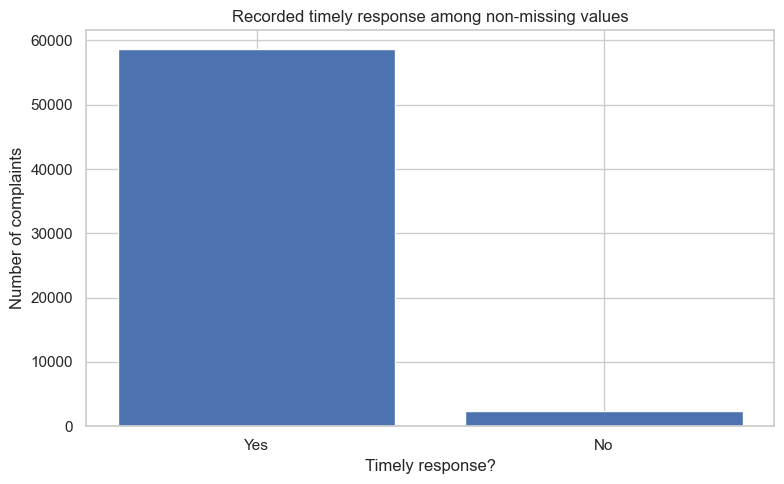

In [14]:
timely_counts = df["Timely response?"].value_counts(dropna=False).rename_axis(
    "Timely response indicator"
).reset_index(name="Complaints")
timely_counts["Percentage of all records"] = (timely_counts["Complaints"] / len(df) * 100).round(2)
display(timely_counts)

timely_known = df["Timely response?"].notna().sum()
timely_yes = (df["Timely response?"] == "Yes").sum()
timely_no = (df["Timely response?"] == "No").sum()
timely_yes_pct_known = timely_yes / timely_known * 100 if timely_known else np.nan

print(f"Known timely-response records: {timely_known:,}")
print(f"Marked Yes: {timely_yes:,}")
print(f"Marked No: {timely_no:,}")
print(f"Blank/missing: {df['Timely response?'].isna().sum():,}")
print(f"Yes among known Yes/No records: {timely_yes_pct_known:.2f}%")

plt.figure(figsize=(8, 5))
timely_plot = df["Timely response?"].value_counts().reindex(["Yes", "No"])
plt.bar(timely_plot.index, timely_plot.values)
plt.title("Recorded timely response among non-missing values")
plt.xlabel("Timely response?")
plt.ylabel("Number of complaints")
plt.tight_layout()
plt.show()

### 7.9 Complaint-forwarding intervals

The forwarding interval is calculated as `Date received − Date submitted`, in calendar days. The distribution is expected to be right-skewed if many complaints are forwarded on the same day while a smaller number take longer. Median and interquartile range are therefore reported alongside the mean and standard deviation.

This measure ends when the CFPB forwards the complaint to the company. It does not measure how long the company takes to respond or resolve the complaint.

,Forwarding days
count,62516.000000
mean,1.224886
std,5.649298
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
90%,2.000000
95%,5.000000
99%,25.000000


Forwarding interval frequency:


,Complaints
Days,
0,49634
1,5575
2,1590
3,1266
4,826
5,549
6,386
7,247
8,186


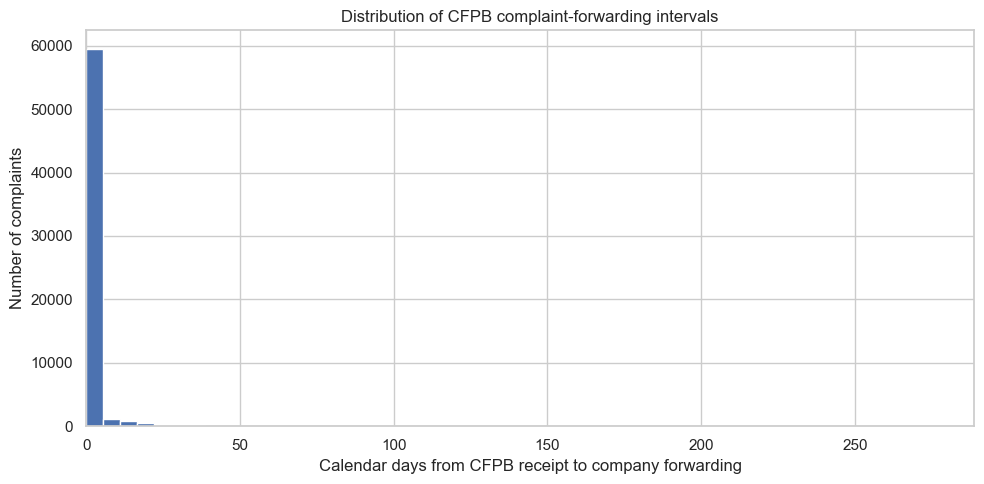

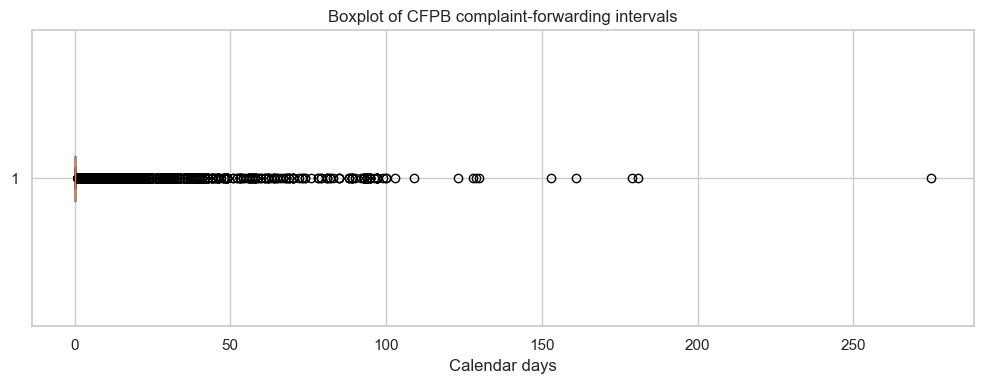

In [15]:
forwarding_summary = df["Forwarding days"].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).to_frame()
display(forwarding_summary)

print("Forwarding interval frequency:")
display(df["Forwarding days"].value_counts().sort_index().head(20).rename_axis("Days").to_frame("Complaints"))

plt.figure(figsize=(10, 5))
plt.hist(df["Forwarding days"].dropna(), bins=50)
plt.title("Distribution of CFPB complaint-forwarding intervals")
plt.xlabel("Calendar days from CFPB receipt to company forwarding")
plt.ylabel("Number of complaints")
plt.xlim(left=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.boxplot(df["Forwarding days"].dropna(), vert=False)
plt.title("Boxplot of CFPB complaint-forwarding intervals")
plt.xlabel("Calendar days")
plt.tight_layout()
plt.show()

### 7.10 Forwarding intervals by financial product

The median and interquartile range are compared across product categories. Product groups with very small sample sizes should be interpreted cautiously. The table is descriptive; the Kruskal–Wallis test in the inferential section evaluates whether the distributions differ overall.

,complaints,median_days,mean_days,q1,q3
Product,,,,,
Checking or savings account,24814,0.0,1.23,0.0,1.0
Credit card or prepaid card,16197,0.0,1.13,0.0,0.0
"Credit reporting, credit repair services, or other personal consumer reports",7710,0.0,0.74,0.0,0.0
Debt collection,2736,0.0,1.64,0.0,0.0
"Money transfer, virtual currency, or money service",3453,0.0,1.06,0.0,0.0
Mortgage,6601,0.0,1.86,0.0,1.0
"Payday loan, title loan, or personal loan",333,0.0,1.68,0.0,1.0
Student loan,39,0.0,2.13,0.0,1.5
Vehicle loan or lease,633,0.0,1.44,0.0,0.0


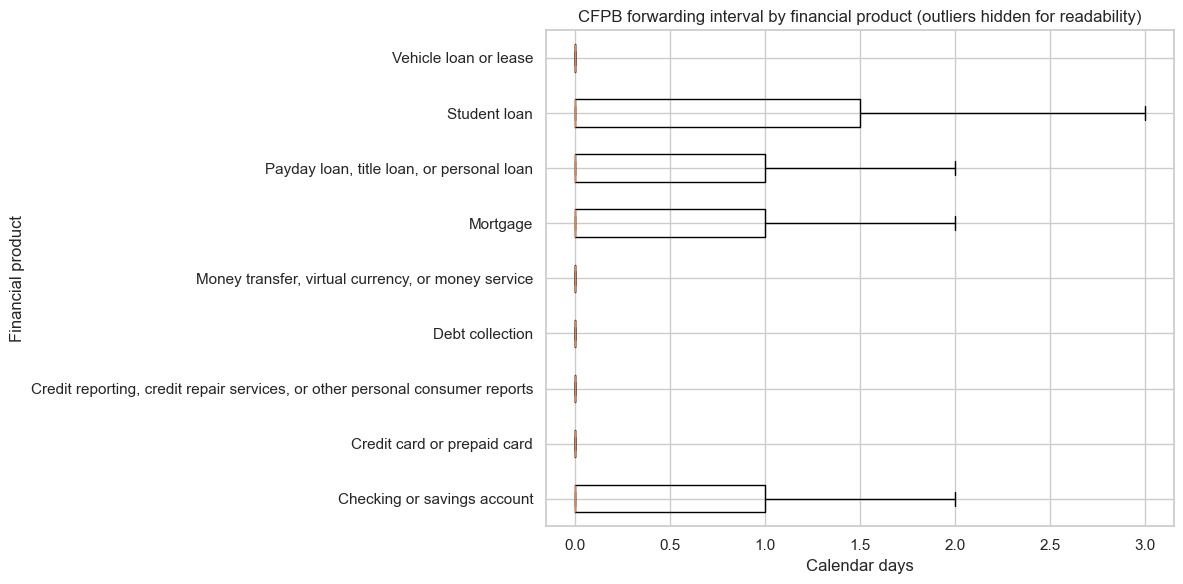

In [16]:
forwarding_by_product = (
    df.dropna(subset=["Forwarding days", "Product"])
      .groupby("Product")["Forwarding days"]
      .agg(complaints="count", median_days="median", mean_days="mean",
           q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75))
      .sort_values("median_days")
      .round(2)
)
display(forwarding_by_product)

plt.figure(figsize=(12, 6))
box_data = [g["Forwarding days"].dropna().to_numpy() for _, g in df.groupby("Product")]
box_labels = [name for name, _ in df.groupby("Product")]
plt.boxplot(box_data, vert=False, labels=box_labels, showfliers=False)
plt.title("CFPB forwarding interval by financial product (outliers hidden for readability)")
plt.xlabel("Calendar days")
plt.ylabel("Financial product")
plt.tight_layout()
plt.show()

## 8. Statistical analysis

### 8.1 Test selection and assumptions

- **Kruskal–Wallis:** non-parametric comparison of forwarding-interval distributions across independent product groups. It is used because forwarding intervals are discrete and strongly skewed. The test requires independent observations and at least ordinal/continuous outcomes.
- **Chi-square test of independence:** assesses association between categorical variables. Expected cell counts are checked; sparse categories are grouped where necessary for the specific test.
- **Spearman correlation:** assesses a monotonic relationship between chronological month index and monthly complaint count. It does not establish causation and does not account for every possible time-series feature.

All tests use α = 0.05. Results are interpreted with effect sizes where feasible.

### 8.2 RQ1 – Do forwarding intervals differ across product categories?

**H₀:** Forwarding-interval distributions are the same across product categories.  
**H₁:** At least one product category has a different forwarding-interval distribution.

Kruskal–Wallis is applied to product groups with at least 30 valid forwarding-interval observations. This minimum is a practical stability rule for this analysis, not a universal statistical threshold. The test is an omnibus test: a significant result indicates that at least one group differs, but does not identify which pairs differ.

In [17]:
MIN_GROUP_N = 30
groups = [
    group["Forwarding days"].dropna().to_numpy()
    for _, group in df.groupby("Product")
    if group["Forwarding days"].notna().sum() >= MIN_GROUP_N
]
group_names = [
    name for name, group in df.groupby("Product")
    if group["Forwarding days"].notna().sum() >= MIN_GROUP_N
]

if len(groups) >= 2:
    kw_stat, kw_p = stats.kruskal(*groups)
    n_total = sum(len(g) for g in groups)
    k_groups = len(groups)
    # Epsilon-squared effect size approximation for Kruskal-Wallis
    epsilon_sq = (kw_stat - k_groups + 1) / (n_total - k_groups) if n_total > k_groups else np.nan
    print(f"Groups tested: {k_groups}")
    print(f"Observations tested: {n_total:,}")
    print(f"Kruskal-Wallis H = {kw_stat:.4f}")
    print(f"p-value {format_p(kw_p)}")
    print(f"Approximate epsilon-squared = {epsilon_sq:.4f}")
    print("Decision:", "Reject H0" if kw_p < 0.05 else "Fail to reject H0")
else:
    print("Insufficient eligible groups for Kruskal-Wallis test.")

Groups tested: 9
Observations tested: 62,516
Kruskal-Wallis H = 1527.3881
p-value < 0.001
Approximate epsilon-squared = 0.0243
Decision: Reject H0


### 8.3 RQ2 – Is recorded company response associated with product category?

**H₀:** Product category and recorded company response category are independent.  
**H₁:** Product category and recorded company response category are associated.

The `Company response to consumer` field is used because it records the response/status classification. The small `Closed` category is combined with the broader `Other/rare status` grouping for this test to reduce sparse expected counts. Missing values, if any, are excluded from the test and reported separately.

In [18]:
response_test = df[["Product", "Company response to consumer"]].dropna().copy()

# The category "Closed" has only eight records, so it is excluded from this
# inferential test to avoid extremely small expected frequencies.
response_test = response_test[response_test["Company response to consumer"] != "Closed"]

# Product categories with fewer than 1,000 records are combined into one
# "Other products" group for this test only. The original descriptive tables
# above retain all product categories separately.
product_sizes = response_test["Product"].value_counts()
response_test["Product group"] = response_test["Product"].where(
    response_test["Product"].map(product_sizes) >= 1000, "Other products"
)
response_ct = pd.crosstab(response_test["Product group"], response_test["Company response to consumer"])

chi2_resp, p_resp, dof_resp, expected_resp = stats.chi2_contingency(response_ct)
min_expected_resp = expected_resp.min()
cramers_v_resp = np.sqrt(
    chi2_resp / (response_ct.to_numpy().sum() * min(response_ct.shape[0]-1, response_ct.shape[1]-1))
)

print("Contingency table (rare response and low-volume product groups combined/excluded as documented):")
display(response_ct)
print(f"Chi-square = {chi2_resp:.4f}; df = {dof_resp}; p-value {format_p(p_resp)}")
print(f"Minimum expected cell count = {min_expected_resp:.3f}")
print(f"Cramér's V = {cramers_v_resp:.4f}")
print("Decision:", "Reject H0" if p_resp < 0.05 else "Fail to reject H0")
if min_expected_resp < 5:
    print("Assumption warning: at least one expected cell count is below 5; interpret the chi-square approximation cautiously.")
else:
    print("Expected-frequency check: all expected cell counts are at least 5.")

Contingency table (rare response and low-volume product groups combined/excluded as documented):


Company response to consumer,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief,In progress
Product group,,,,
Checking or savings account,14836,8027,1241,710
Credit card or prepaid card,9361,4798,1621,412
"Credit reporting, credit repair services, or other personal consumer reports",6067,273,1178,190
Debt collection,2367,111,209,49
"Money transfer, virtual currency, or money service",2709,634,41,69
Mortgage,4928,750,876,46
Other products,776,104,107,18


Chi-square = 5549.3281; df = 18; p-value < 0.001
Minimum expected cell count = 24.020
Cramér's V = 0.1720
Decision: Reject H0
Expected-frequency check: all expected cell counts are at least 5.


### 8.4 RQ3 – Has timely-response status varied across reporting years?

**H₀:** Timely-response status is independent of reporting year.  
**H₁:** Timely-response status is associated with reporting year.

Only explicit `Yes` and `No` values are included. Blank values are excluded, not treated as “No”. The first and last years are partial calendar years, so any observed year differences should be interpreted with the unequal observation periods in mind.

In [19]:
timely_test = df[df["Timely response?"].isin(["Yes", "No"])].copy()
timely_ct = pd.crosstab(timely_test["Year"], timely_test["Timely response?"])
chi2_timely, p_timely, dof_timely, expected_timely = stats.chi2_contingency(timely_ct)
min_expected_timely = expected_timely.min()
cramers_v_timely = np.sqrt(
    chi2_timely / (timely_ct.to_numpy().sum() * min(timely_ct.shape[0]-1, timely_ct.shape[1]-1))
)

timely_year_pct = (
    timely_test.assign(Yes=(timely_test["Timely response?"] == "Yes"))
    .groupby("Year")["Yes"].agg(["sum", "count", "mean"])
)
timely_year_pct["Yes percentage"] = (timely_year_pct["mean"] * 100).round(2)
display(timely_ct)
display(timely_year_pct[["sum", "count", "Yes percentage"]])

print(f"Chi-square = {chi2_timely:.4f}; df = {dof_timely}; p-value {format_p(p_timely)}")
print(f"Minimum expected cell count = {min_expected_timely:.3f}")
print(f"Cramér's V = {cramers_v_timely:.4f}")
print("Decision:", "Reject H0" if p_timely < 0.05 else "Fail to reject H0")
if min_expected_timely < 5:
    print("Assumption warning: at least one expected cell count is below 5; interpret cautiously.")

Timely response?,No,Yes
Year,,
2017,9,5385
2018,12,7860
2019,7,7068
2020,62,8880
2021,1224,9925
2022,567,12386
2023,522,7115


,sum,count,Yes percentage
Year,,,
2017,5385,5394,99.83
2018,7860,7872,99.85
2019,7068,7075,99.90
2020,8880,8942,99.31
2021,9925,11149,89.02
2022,12386,12953,95.62
2023,7115,7637,93.16


Chi-square = 2662.5027; df = 6; p-value < 0.001
Minimum expected cell count = 212.412
Cramér's V = 0.2089
Decision: Reject H0


### 8.5 RQ4 – Is there a monotonic trend in monthly complaint volume?

**H₀:** There is no monotonic association between time and monthly complaint volume.  
**H₁:** There is a monotonic association between time and monthly complaint volume.

A Spearman rank correlation is calculated between the chronological month index and the number of complaints in each month. The analysis uses every calendar month between the first and last observed dates, including any month with zero complaints. This test identifies a monotonic association; it is not a forecasting model and does not account for seasonality, structural breaks or autocorrelation.

In [20]:
monthly_for_test = monthly_counts.copy()
monthly_for_test["Month index"] = np.arange(len(monthly_for_test))
rho, p_trend = stats.spearmanr(monthly_for_test["Month index"], monthly_for_test["Complaints"])

print(f"Months analysed: {len(monthly_for_test)}")
print(f"Spearman rho = {rho:.4f}")
print(f"p-value {format_p(p_trend)}")
print("Decision:", "Reject H0" if p_trend < 0.05 else "Fail to reject H0")

Months analysed: 76
Spearman rho = 0.7784
p-value < 0.001
Decision: Reject H0


## 9. Consolidated findings and business interpretation

The following cells generate concise, data-led findings directly from the executed analysis. This avoids manually inserting values that could become inconsistent if the source data or cleaning choices change.

In [21]:
# Dynamic descriptive findings
top_product = product_counts.iloc[0]
top_issue = issue_counts.iloc[0]
top_response = response_counts.sort_values("Complaints", ascending=False).iloc[0]
median_forward = df["Forwarding days"].median()
mean_forward = df["Forwarding days"].mean()
zero_forward_pct = (df["Forwarding days"].eq(0).mean() * 100)
known_timely_pct = timely_yes_pct_known

print("FINDING 1 – Complaint concentration")
print(f"The most frequently represented product is '{top_product['Product']}', "
      f"with {int(top_product['Complaints']):,} complaints "
      f"({top_product['Percentage']:.2f}% of all records).")

print("\nFINDING 2 – Most common reported issue")
print(f"The most frequently recorded issue is '{top_issue['Issue']}', "
      f"with {int(top_issue['Complaints']):,} complaints "
      f"({top_issue['Percentage']:.2f}% of all records).")

print("\nFINDING 3 – Recorded company response")
print(f"The most common recorded response/status is '{top_response['Recorded company response']}', "
      f"with {int(top_response['Complaints']):,} complaints "
      f"({top_response['Percentage']:.2f}% of all records).")

print("\nFINDING 4 – CFPB forwarding interval")
print(f"The median forwarding interval is {median_forward:.0f} day(s), compared with a mean of "
      f"{mean_forward:.2f} days. {zero_forward_pct:.2f}% of complaints were forwarded on the "
      "same calendar day. This is not company resolution time.")

print("\nFINDING 5 – Timely-response indicator")
print(f"Among records with an explicit Yes/No indicator, {known_timely_pct:.2f}% are marked Yes. "
      f"{df['Timely response?'].isna().sum():,} records have a blank indicator and are not "
      "classified as No.")

print("\nINFERENTIAL TEST SUMMARY")
print(f"RQ1 Kruskal–Wallis p-value {format_p(kw_p)}" if 'kw_p' in globals() else "RQ1 test not run")
print(f"RQ2 Product × response chi-square p-value {format_p(p_resp)}" if 'p_resp' in globals() else "RQ2 test not run")
print(f"RQ3 Year × timely response chi-square p-value {format_p(p_timely)}" if 'p_timely' in globals() else "RQ3 test not run")
print(f"RQ4 Spearman trend p-value {format_p(p_trend)}" if 'p_trend' in globals() else "RQ4 test not run")

FINDING 1 – Complaint concentration
The most frequently represented product is 'Checking or savings account', with 24,814 complaints (39.69% of all records).

FINDING 2 – Most common reported issue
The most frequently recorded issue is 'Managing an account', with 15,109 complaints (24.17% of all records).

FINDING 3 – Recorded company response
The most common recorded response/status is 'Closed with explanation', with 41,044 complaints (65.65% of all records).

FINDING 4 – CFPB forwarding interval
The median forwarding interval is 0 day(s), compared with a mean of 1.22 days. 79.39% of complaints were forwarded on the same calendar day. This is not company resolution time.

FINDING 5 – Timely-response indicator
Among records with an explicit Yes/No indicator, 96.06% are marked Yes. 1,494 records have a blank indicator and are not classified as No.

INFERENTIAL TEST SUMMARY
RQ1 Kruskal–Wallis p-value < 0.001
RQ2 Product × response chi-square p-value < 0.001
RQ3 Year × timely response chi

### 9.1 Interpretation for financial-services stakeholders

The descriptive analysis can help a financial institution prioritise complaint monitoring by product and issue, identify periods with higher complaint volumes, and understand the distribution of recorded response statuses. Product-level complaint counts should be interpreted alongside product customer/account volumes before being treated as comparative risk or service-quality rates.

If the statistical tests identify associations, stakeholders should treat them as signals for further investigation. For example, a product-response association may indicate that response classifications differ across products, but it does not explain why the difference exists. Operational processes, customer mix, complaint complexity, policy changes and recording practices may all contribute.

### 9.2 Practical recommendations

1. **Prioritise high-volume product and issue combinations.** Review the most frequently reported combinations and investigate recurring root causes using case-level records and operational teams.
2. **Monitor complaint trends consistently.** Use monthly reporting and annotate policy, product, system or process changes that may explain shifts.
3. **Track forwarding and resolution separately.** The available forwarding interval ends when the CFPB sends the complaint to the company. Add internal timestamps for acknowledgement, investigation, final response and resolution to measure the full service journey.
4. **Improve response-status monitoring.** Preserve the distinction between in-progress cases and explicit timely-response outcomes; investigate missing indicator values before using them in performance reporting.
5. **Use denominators for fair product comparisons.** Where possible, obtain the number of active customers/accounts or transactions per product and calculate complaint rates, rather than relying on raw counts alone.
6. **Validate findings with qualitative case review.** Examine representative complaint narratives and case outcomes before recommending process or policy changes.

## 10. Limitations and alternative explanations

1. **Dataset scope:** The supplied extract does not contain a company-name field. The Bank of America label comes from the project brief and cannot be independently checked within this 12-column file.
2. **Partial years:** 2017 begins on 1 May and 2023 ends on 28 August. Raw annual totals are not directly comparable with full calendar years.
3. **No exposure denominator:** The file does not include product customer counts, account counts or transaction volumes. High complaint counts may reflect a larger customer base rather than a higher complaint rate.
4. **Reported complaints are not verified findings:** A complaint records a consumer-reported issue and does not establish misconduct or a regulatory breach.
5. **Missing fields:** Sub-issue, public response and timely-response values contain missing entries. Missingness may be related to product design, optional disclosure or case status.
6. **Forwarding interval is not resolution time:** The available dates measure the CFPB-to-company forwarding interval only. They do not reveal the time taken by the company to investigate or resolve a case.
7. **Statistical assumptions:** Chi-square tests rely on adequate expected cell counts and independent observations. Kruskal–Wallis assumes independent groups. Large samples can make small differences statistically significant.
8. **Time-series limitations:** Monthly complaint volumes may exhibit seasonality, autocorrelation, reporting delays and structural breaks. Spearman correlation is a simple monotonic-trend test, not a complete time-series model.
9. **Unobserved factors:** Customer demographics, account tenure, product usage, complaint severity, channel-specific behaviour and policy changes are not available in the supplied fields.
10. **No causal inference:** The analysis is observational. Associations cannot establish that a product, response category or time period caused a particular complaint outcome.
11. **Forecasting and dashboard scope:** This notebook analyses historical trends but does not fit or validate a complaint-volume forecasting model, nor does it deploy an interactive dashboard or AI assistant. Reliable forecasting would require a separate time-series modelling exercise with time-ordered validation; dashboards and AI assistants would require additional design and validation work.

## 11. Reproducibility and quality assurance

The final checks confirm that the prepared dataset retains the expected number of records, the candidate complaint identifier is unique, the original source data remains available in `raw`, and the principal derived interval has no negative values. The notebook should be re-run from the first cell to reproduce the tables, plots and statistical results.

In [22]:
qa_checks = pd.DataFrame({
    "Check": [
        "Expected row count from project brief",
        "Prepared row count equals raw row count",
        "Complaint ID is unique",
        "No negative forwarding intervals",
        "Date columns parsed without missing values",
        "Original raw dataframe preserved"
    ],
    "Result": [
        len(df) == 62516,
        len(df) == len(raw),
        df["Complaint ID"].is_unique,
        (df["Forwarding days"].dropna() >= 0).all(),
        df[["Date submitted", "Date received"]].notna().all().all(),
        isinstance(raw, pd.DataFrame) and "Forwarding days" not in raw.columns
    ]
})
qa_checks["Status"] = np.where(qa_checks["Result"], "PASS", "REVIEW")
display(qa_checks)

if not qa_checks["Result"].all():
    print("One or more QA checks require review. Investigate before submission.")
else:
    print("All configured QA checks passed.")

,Check,Result,Status
0,Expected row count from project brief,True,PASS
1,Prepared row count equals raw row count,True,PASS
2,Complaint ID is unique,True,PASS
3,No negative forwarding intervals,True,PASS
4,Date columns parsed without missing values,True,PASS
5,Original raw dataframe preserved,True,PASS


All configured QA checks passed.


## 12. Conclusion

This notebook provides a reproducible descriptive and inferential analysis of the supplied consumer complaint extract. It examines complaint volume over time, the products and issues most frequently represented, recorded company response classifications, timely-response indicators and CFPB complaint-forwarding intervals.

The findings should be used as a monitoring and investigation aid rather than as proof of misconduct or causal explanation. Stronger operational conclusions would require customer/account denominators, complaint narratives, company investigation timestamps, case outcomes and relevant business context.
